# Introduction to Statistics

Companion notebook for [Introduction to Statistics](../../notes/foundations/introduction_to_statistics.md).

The key ideas are the difference between a **population** (with parameters such as $\mu$ and $\sigma$) and a **sample** (with statistics such as $\bar{x}$ and $s$), and how sampling method relates to bias. We explore them by simulation with a fixed seed.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

rng = np.random.default_rng(42)
plt.rcParams["figure.figsize"] = (7, 3.5)

## 1. A population and one random sample

We define a small population of 20 heights (in inches) and draw a simple random sample of size 5 without replacement. The population mean $\mu$ and standard deviation $\sigma$ are *parameters*; $\bar{x}$ and $s$ computed from the sample are *statistics*.

In [2]:
population = np.array([68, 70, 72, 66, 74, 71, 69, 75, 73, 67,
                       70, 72, 68, 70, 71, 69, 72, 74, 68, 70])
sample = rng.choice(population, size=5, replace=False)

print("population: mu    =", population.mean(), " sigma =", round(population.std(ddof=0), 3))
print("sample    : xbar  =", sample.mean(), " s     =", round(sample.std(ddof=1), 3))
print("sample values:", sample)

population: mu    = 70.45  sigma = 2.397
sample    : xbar  = 71.0  s     = 1.414
sample values: [70 73 72 70 70]


## 2. Sampling variability

A different sample would give a different $\bar{x}$. Repeating the draw many times shows the statistic varying around the parameter. This is the starting point for inference.

average of sample means: 70.439 (population mean 70.45 )
sd of sample means     : 0.954


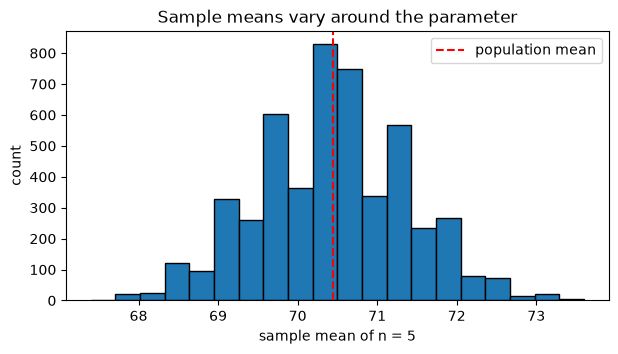

In [3]:
means = np.array([rng.choice(population, 5, replace=False).mean() for _ in range(5000)])
print("average of sample means:", round(means.mean(), 3), "(population mean", population.mean(), ")")
print("sd of sample means     :", round(means.std(ddof=1), 3))

plt.hist(means, bins=20, edgecolor="black")
plt.axvline(population.mean(), color="red", linestyle="--", label="population mean")
plt.xlabel("sample mean of n = 5"); plt.ylabel("count"); plt.legend()
plt.title("Sample means vary around the parameter")
plt.show()

## 3. Bias from a non-representative sampling method

Suppose the quantity of interest is the average income in a town, but the survey only reaches people reachable through a high-income channel (selection bias). A bigger sample does not fix this. We compare a random sample with a biased one on a simulated right-skewed income population.

In [4]:
income = rng.lognormal(mean=10.5, sigma=0.6, size=100_000)  # simulated incomes
true_mean = income.mean()

def random_sample(n):
    return rng.choice(income, n, replace=False)

def biased_sample(n):
    # only the top 40% of earners can be reached
    reachable = income[income > np.quantile(income, 0.6)]
    return rng.choice(reachable, n, replace=False)

print(f"true mean income     : {true_mean:10.0f}")
for n in (50, 500, 5000):
    print(f"n={n:5d} random mean : {random_sample(n).mean():10.0f}   biased mean : {biased_sample(n).mean():10.0f}")

true mean income     :      43428
n=   50 random mean :      43333   biased mean :      69095
n=  500 random mean :      43601   biased mean :      68790
n= 5000 random mean :      43447   biased mean :      68968


The random sample's mean approaches the truth as $n$ grows, while the biased sample converges to the wrong value. Sample size reduces *variance*, not *bias*.

## 4. Stratified versus simple random sampling

Suppose a school has 600 undergraduates (mean score 70) and 400 graduate students (mean score 80). A proportional stratified sample of 100 takes 60 and 40, which guarantees the correct group mix, whereas a simple random sample of 100 has random group counts.

In [5]:
scores = np.concatenate([rng.normal(70, 8, 600), rng.normal(80, 8, 400)])
group = np.array([0] * 600 + [1] * 400)
true_mean = scores.mean()

def srs():
    return scores[rng.choice(1000, 100, replace=False)].mean()

def stratified():
    a = rng.choice(scores[group == 0], 60, replace=False)
    b = rng.choice(scores[group == 1], 40, replace=False)
    return np.concatenate([a, b]).mean()

srs_means = np.array([srs() for _ in range(4000)])
str_means = np.array([stratified() for _ in range(4000)])
print("true mean:", round(true_mean, 2))
print("SRS        mean of estimates:", round(srs_means.mean(), 2), " sd:", round(srs_means.std(), 3))
print("stratified mean of estimates:", round(str_means.mean(), 2), " sd:", round(str_means.std(), 3))

true mean: 73.75
SRS        mean of estimates: 73.74  sd: 0.884
stratified mean of estimates: 73.76  sd: 0.753


Both are unbiased here, but the stratified estimator has a smaller standard deviation because the group proportions are fixed.

## 5. Random assignment balances confounders

In an experiment, random assignment allocates sampled participants to treatment or control. Below, a confounder (age) is not controlled by us, yet random assignment makes the two groups similar on average, whereas self-selection (older people choose treatment) does not.

In [6]:
age = rng.normal(45, 12, 2000)

# Random assignment
treat_rand = rng.permutation(2000) < 1000
# Self-selection: older people more likely to choose treatment
treat_self = rng.random(2000) < 1 / (1 + np.exp(-(age - 45) / 5))

for label, t in [("random assignment", treat_rand), ("self-selection", treat_self)]:
    print(f"{label:18s} mean age treated={age[t].mean():5.1f}  control={age[~t].mean():5.1f}")

random assignment  mean age treated= 45.2  control= 44.9
self-selection     mean age treated= 52.8  control= 37.7
